# 04 · Appendix: eligible 8-K mentions of blockchain and AI

> Run after notebooks 01–03, from inside the `code` folder. Notebook 06 re-tests these
> results allowing for event clustering in calendar time.

> **Appendix.** A keyword in an 8-K is not necessarily a new technology initiative (it can be an existing
> product, a risk factor, a counterparty or general commentary), the 24-month rule allows re-entry, and filing
> dates can lag press releases. This analysis is therefore an appendix, under its exact definition: **the first
> eligible 8-K mention after 24 months of silence**. It does not measure first adoption or a first public
> announcement, it is not pooled with the renames, and its larger sample does not replace the small rename samples.

**Why this extension?** On the major exchanges only 4 firms renamed themselves with a Blockchain word and 14
with an AI word, too few for strong tests (RQ2/RQ3 in notebook 03). Many more firms joined these hypes
*without* renaming, by announcing blockchain or AI activities. Following the literature on the 2017–18
blockchain hype (e.g. Cahill et al., 2020, *"I am a blockchain too"*), we study the market reaction to a
firm's **first eligible 8-K mention after 24 months of silence** of the buzzword.

**Appendix question (RQ5).** Do firms' first eligible 8-K mentions of blockchain or AI after 24 months of
silence earn abnormal returns and trading volume, and does the reaction differ between the Blockchain and the AI
wave?

| Step | What happens |
|---|---|
| 1 | Load the 8-K filings that mention the buzzwords (**EDGAR full-text search** results, 2001+ coverage) |
| 2 | One row per filing; link the filer's **CIK → GVKEY → PERMNO** with CCM links valid on the filing date |
| 3 | Keep CRSP common stock on NYSE / NYSE American / Nasdaq (same universe as the rename sample) |
| 4 | **Eligible-mention events**: the first in-wave 8-K mentioning the buzzword with no such 8-K in the previous 24 months |
| 5 | Load the event firms' daily stock data (CRSP) |
| 6 | Event study with the shared module `buzzword_event_study.py` (same engine as notebook 03) |
| 7 | Blockchain vs AI: bootstrap and regressions with firm controls |
| 8 | Comparison with the rename events; export |

**Definitions, fixed before looking at any returns**
* Blockchain wave 2016–2020, terms "blockchain", "bitcoin", "cryptocurrency". AI wave 2021–2025, terms
  "artificial intelligence", "generative AI". The search starts two years earlier (2014 / 2019) so that the
  24-month novelty rule can be checked.
* Event date = 8-K filing date (day 0 = first trading day on/after it).
* Excluded from the main sample: blank-check companies (SIC 6770, "Acquisition" shells), whose 8-Ks describe a
  *target's* business, and firms that renamed with the buzzword within ±90 days (already in the rename sample).
* Robustness: press-release 8-Ks only (an EX-99 exhibit mentions the term), the market-adjusted model, and
  including the renamed firms.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pandas.plotting import scatter_matrix
from scipy import stats
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import buzzword_event_study as es

np.random.seed(42)
random_state = 42
rng = np.random.default_rng(random_state)
set_config(transform_output="pandas")  # sklearn transformers return DataFrames
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rc("axes", titlesize=12, labelsize=11)

In [2]:
# ---- paths: run the notebooks from inside the code/ folder ----
base_dir = Path.cwd().parent                                  # project folder (the notebooks run from code/)
data_dir = base_dir / "data"                                  # raw input files (described in notebook 01)
wrds_dir = data_dir / "raw_data" / "wrds"                     # raw WRDS extracts
edgar_dir = data_dir / "raw_data" / "edgar_fts"               # EDGAR full-text search extract
event_dates_dir = data_dir / "event_dates"                    # hand-collected dates + SEC scan results (inputs)
event_dates_out_dir = base_dir / "event_dates"                # event-date table produced by notebook 02
processed_dir = base_dir / "processed"                        # intermediate tables passed between notebooks
output_dir = base_dir / "output"                              # result tables and figures
for folder in [processed_dir, output_dir, event_dates_out_dir, edgar_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- study design ----
study_start_year, study_end_year = 1990, 2025
eligible_exchanges = ["N", "A", "Q"]            # NYSE, NYSE American, Nasdaq
themes = ["Dot-com", "Blockchain", "AI"]         # Dot-com first = reference category in RQ3
theme_colors = {"Dot-com": "#2a78b5", "Blockchain": "#e08a1e", "AI": "#3a9e5f"}
wave_periods = {"Dot-com": (1995, 2002), "Blockchain": (2016, 2020), "AI": (2021, 2025)}
wave_reference_year = {"Dot-com": 1995, "Blockchain": 2017, "AI": 2022}   # Netscape IPO, Bitcoin boom, ChatGPT

# event-study design (estimation window, windows, tests): see buzzword_event_study.py

# ---- extension design ----
themes = ["Blockchain", "AI"]            # Blockchain = reference category in the comparison
extension_waves = {
    "Blockchain": {"terms": ["blockchain", "bitcoin", "cryptocurrency"], "search_start": "2014-01-01",
                   "start": "2016-01-01", "end": "2020-12-31"},
    "AI": {"terms": ["artificial intelligence", "generative AI"], "search_start": "2019-01-01",
           "start": "2021-01-01", "end": "2025-12-31"},
}
novelty_days = 730                       # no buzzword 8-K in the previous 24 months
rename_overlap_days = 90
hits_file = edgar_dir / "edgar_fts_8k_hits.csv.gz"
daily_file = wrds_dir / "crsp_daily_announcement_firms.csv.gz"

## Step 1: EDGAR full-text search
EDGAR full-text search (efts.sec.gov) returns every 8-K document (main form and exhibits) that contains the
search phrase. Each hit carries the filer's CIK, the filing date, the accession number, the document type
(e.g. EX-99.1 = press release) and the filer's SIC code. The search was run month by month; the results are in `data/raw_data/edgar_fts/`.

In [3]:
hits = pd.read_csv(hits_file, dtype={"ciks": str, "sics": str, "items": str})
hits["file_date"] = pd.to_datetime(hits["file_date"])
print(f"{len(hits):,} matching documents in {hits['adsh'].nunique():,} 8-K filings")
hits.groupby(["wave", "term"]).agg(documents=("adsh", "size"), filings=("adsh", "nunique"))

18,978 matching documents in 14,516 8-K filings


documents  filings
wave       term                                       
AI         artificial intelligence      14195    12041
           generative AI                 1727     1551
Blockchain bitcoin                        686      495
           blockchain                    1781     1329
           cryptocurrency                 589      466

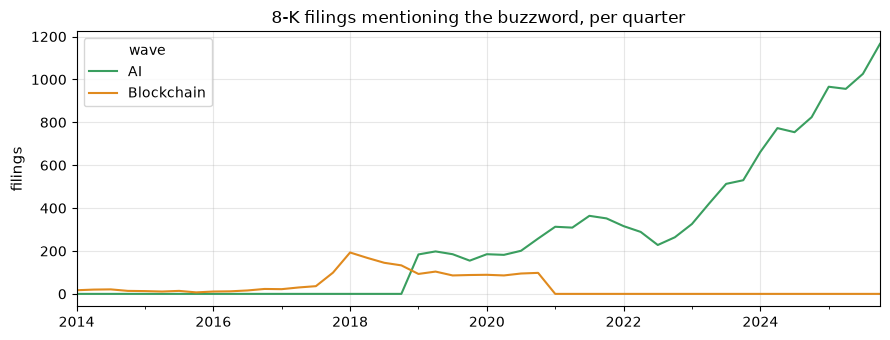

In [4]:
# How did buzzword mentions in 8-Ks evolve? (exploration in the spirit of Tutorial 4)
monthly = (hits.drop_duplicates(["wave", "adsh"]).set_index("file_date").groupby("wave")
           .resample("QE").size().unstack(0).fillna(0))
ax = monthly.plot(figsize=(9, 3.5), color=[theme_colors.get(c, "grey") for c in monthly.columns])
ax.set(title="8-K filings mentioning the buzzword, per quarter", xlabel="", ylabel="filings")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / "ext_8k_mentions_per_quarter.png", dpi=150)
plt.show()

## Steps 2–3: Filings → CRSP firms (identifiers and universe)
* One row per (wave, filing). A filing can have several co-registrant CIKs; each one is linked.
* **CIK → GVKEY → PERMNO** through `ccm_permno_gvkey_cik` (Compustat CIK + CCM link history), requiring the
  link to be **valid on the filing date**. This follows the same identifier logic as notebook 02.
* The PERMNO must be eligible on the filing date: ordinary common stock on NYSE, NYSE American or Nasdaq.

In [5]:
def build_filings(hits):
    """
    Collapse document-level hits to one row per wave and 8-K filing.

    Parameters
    ----------
    hits : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        ``wave``, ``adsh``, ``cik`` (one row per co-registrant), ``file_date``, matched terms, whether a press
        release (EX-99) matched, filer name and SIC codes.
    """
    hits = hits.assign(press_release=hits["file_type"].fillna("").str.upper().str.startswith("EX-99"))
    filings = hits.groupby(["wave", "adsh"]).agg(
        ciks=("ciks", "first"), file_date=("file_date", "min"), terms=("term", lambda s: ";".join(sorted(set(s)))),
        documents=("document", "nunique"), press_release=("press_release", "max"),
        display_names=("display_names", "first"), sics=("sics", "first"), items=("items", "first")).reset_index()
    filings["cik"] = filings["ciks"].str.split(";")
    filings = filings.explode("cik")
    filings["cik"] = filings["cik"].str.lstrip("0")
    return filings.drop(columns="ciks")


def link_filings_to_crsp(filings, cik_links, security):
    """
    Attach the PERMNO of an eligible listed common stock valid on the filing date.

    Parameters
    ----------
    filings : pandas.DataFrame
    cik_links : pandas.DataFrame
        PERMNO-GVKEY-CIK links with validity dates.
    security : pandas.DataFrame
        CRSP security information history.

    Returns
    -------
    pandas.DataFrame
        Linked filings with ``permno`` and ``gvkey``.
    """
    links = cik_links.dropna(subset=["cik"]).assign(
        cik=lambda d: d["cik"].astype(str).str.lstrip("0"),
        link_start=lambda d: pd.to_datetime(d["linkdt"]),
        link_end=lambda d: pd.to_datetime(d["linkenddt"]).fillna(pd.Timestamp("2099-12-31")))
    linked = filings.merge(links[["cik", "permno", "gvkey", "link_start", "link_end"]], on="cik")
    linked = linked[linked["file_date"].between(linked["link_start"], linked["link_end"])]

    eligible = security[(security["sharetype"] == "NS") & (security["securitytype"] == "EQTY")
                        & (security["securitysubtype"] == "COM") & security["primaryexch"].isin(eligible_exchanges)]
    eligible = eligible.assign(start=pd.to_datetime(eligible["secinfostartdt"]),
                               end=pd.to_datetime(eligible["secinfoenddt"]))[["permno", "start", "end"]]
    linked = linked.merge(eligible, on="permno")
    linked = linked[linked["file_date"].between(linked["start"], linked["end"])]
    return linked.drop_duplicates(["wave", "adsh", "permno"]).drop(columns=["link_start", "link_end", "start", "end"])


security = pd.read_csv(wrds_dir / "crsp_security_info_history.csv.gz", low_memory=False)
cik_links = pd.read_csv(wrds_dir / "ccm_permno_gvkey_cik.csv.gz", dtype={"cik": str})
filings = build_filings(hits)
linked_filings = link_filings_to_crsp(filings, cik_links, security)
print(f"filings: {filings['adsh'].nunique():,} | linked to an eligible CRSP common stock: "
      f"{linked_filings['adsh'].nunique():,} filings of {linked_filings['permno'].nunique():,} firms")

filings: 14,516 | linked to an eligible CRSP common stock: 11,746 filings of 2,047 firms


## Step 4: Eligible-mention events
For each wave and firm, the event is the **first in-wave 8-K mentioning the buzzword with no such 8-K in the
preceding 24 months**. This is a re-entry rule, not "first ever": a firm may have mentioned the word before
the 24-month gap (`prior_mentions_in_search_window` counts those cases). This
mirrors the "theme entry" rule for names. Blank-check shells and firms already in the rename sample (±90 days)
are flagged and excluded from the main sample.

In [6]:
def build_mention_events(linked_filings, rename_events):
    """
    Select each firm's first eligible 8-K mention per wave (24 months of silence) and flag special cases.

    Parameters
    ----------
    linked_filings : pandas.DataFrame
        Output of :func:`link_filings_to_crsp`.
    rename_events : pandas.DataFrame
        Rename events of notebook 02 (to flag overlaps).

    Returns
    -------
    pandas.DataFrame
        One row per (wave, firm) with ``event_date``, flags and an ``in_main_sample`` indicator.
    """
    rows = []
    for (wave, permno), group in linked_filings.sort_values("file_date").groupby(["wave", "permno"]):
        spec = extension_waves[wave]
        dates = group["file_date"].tolist()
        for i, filing in enumerate(group.itertuples()):
            in_wave = pd.Timestamp(spec["start"]) <= filing.file_date <= pd.Timestamp(spec["end"])
            recent = [d for d in dates[:i] if (filing.file_date - d).days <= novelty_days]
            if in_wave and not recent:
                rows.append({"wave": wave, "permno": permno, "gvkey": filing.gvkey, "cik": filing.cik,
                             "adsh": filing.adsh, "event_date": filing.file_date, "terms": filing.terms,
                             "press_release": int(filing.press_release), "company": filing.display_names,
                             "sics": filing.sics, "items": filing.items,
                             "prior_mentions_in_search_window": i})
                break
    events = pd.DataFrame(rows)
    events["blank_check"] = (events["sics"].fillna("").str.contains("6770")
                             | events["company"].str.contains(r"\bACQUISITION\b|\bACQ\b", case=False, regex=True)).astype(int)
    renames = rename_events[["permno", "theme", "event_date"]].rename(columns={"event_date": "rename_date", "theme": "wave"})
    merged = events.merge(renames, on=["permno", "wave"], how="left")
    merged["also_renamed"] = ((merged["event_date"] - merged["rename_date"]).dt.days.abs() <= rename_overlap_days).astype(int)
    events = merged.sort_values("also_renamed", ascending=False).drop_duplicates(["wave", "permno"]).drop(columns="rename_date")
    events["in_main_sample"] = ((events["blank_check"] == 0) & (events["also_renamed"] == 0)).astype(int)
    events = events.sort_values(["event_date", "permno"]).reset_index(drop=True)
    events.insert(0, "event_id", range(1, len(events) + 1))
    # columns expected by the event-study functions of notebook 03
    events["theme"] = events["wave"]
    events["effective_date"] = events["event_date"]
    events["event_date_source"] = "8-K filing date"
    events["old_name"] = events["new_name"] = events["company"].str.split("  ").str[0]
    events["is_spac"] = events["blank_check"]
    events["in_wave_period"] = 1
    return events


rename_events = pd.read_csv(processed_dir / "events.csv", parse_dates=["event_date"])
announcements = build_mention_events(linked_filings, rename_events)
announcements["event_month"] = announcements["event_date"].dt.to_period("M").astype(str)
announcements.to_csv(processed_dir / "announcement_events.csv", index=False)
print(announcements.groupby("wave")[["blank_check", "also_renamed", "in_main_sample", "press_release"]].sum())
print("events per wave:", announcements["wave"].value_counts().to_dict())
re_entry = announcements[announcements["in_main_sample"] == 1].groupby("wave")["prior_mentions_in_search_window"].apply(lambda s: int((s > 0).sum()))
print("main-sample events with an earlier mention before the 24-month gap (re-entries):", re_entry.to_dict())
announcements.head()

            blank_check  also_renamed  in_main_sample  press_release
wave                                                                
AI                  148             4            1583           1457
Blockchain            6             2             152            133
events per wave: {'AI': 1732, 'Blockchain': 160}
main-sample events with an earlier mention before the 24-month gap (re-entries): {'AI': 145, 'Blockchain': 3}


,event_id,wave,permno,gvkey,cik,adsh,event_date,terms,press_release,company,sics,items,prior_mentions_in_search_window,blank_check,also_renamed,in_main_sample,theme,effective_date,event_date_source,old_name,new_name,is_spac,in_wave_period,event_month
0,1,Blockchain,12446.0,185518,1499912,0001144204-16-078205,2016-02-01,bitcoin;blockchain,0,FXCM Inc. (CIK 0001499912),6200,5.02;8.01;9.01,0,0,0,1,Blockchain,2016-02-01,8-K filing date,FXCM Inc.,FXCM Inc.,0,1,2016-02
1,2,Blockchain,91849.0,176928,1383312,0001383312-16-000080,2016-02-05,blockchain,1,"BROADRIDGE FINANCIAL SOLUTIONS, INC. (BR) (C...",7389,7.01;9.01,0,0,0,1,Blockchain,2016-02-05,8-K filing date,"BROADRIDGE FINANCIAL SOLUTIONS, INC.","BROADRIDGE FINANCIAL SOLUTIONS, INC.",0,1,2016-02
2,3,Blockchain,72726.0,10035,93751,0000093751-16-000538,2016-02-24,blockchain,1,"STATE STREET CORP (STT, STT-PG) (CIK 0000093...",6022,7.01;9.01,0,0,0,1,Blockchain,2016-02-24,8-K filing date,STATE STREET CORP,STATE STREET CORP,0,1,2016-02
3,4,Blockchain,12490.0,6066,51143,0001104659-16-099789,2016-02-25,blockchain,0,INTERNATIONAL BUSINESS MACHINES CORP (IBM) (...,3570,7.01,0,0,0,1,Blockchain,2016-02-25,8-K filing date,INTERNATIONAL BUSINESS MACHINES CORP,INTERNATIONAL BUSINESS MACHINES CORP,0,1,2016-02
4,5,Blockchain,89003.0,165993,1136893,0001136893-16-000074,2016-05-10,blockchain,1,"Fidelity National Information Services, Inc. ...",7389,2.02;9.01,0,0,0,1,Blockchain,2016-05-10,8-K filing date,"Fidelity National Information Services, Inc.","Fidelity National Information Services, Inc.",0,1,2016-05


## Step 5: Daily stock data (CRSP)
For each event firm the file holds the trading days from about 400 calendar days before to 30 days after the event
(`data/raw_data/wrds/crsp_daily_announcement_firms.csv.gz`); we check that it covers every event firm.

In [7]:
needed = set(announcements["permno"])
have = set(pd.read_csv(daily_file, usecols=["permno"])["permno"])
print("daily stock file covers all event PERMNOs:", needed <= have)

daily stock file covers all event PERMNOs: True


## Step 6: Event study
Same engine as notebook 03 (`buzzword_event_study.py`): day 0 on the market calendar, complete windows,
pre-event baselines only, t / sign / Wilcoxon / BMP / bootstrap / month-clustered tests.

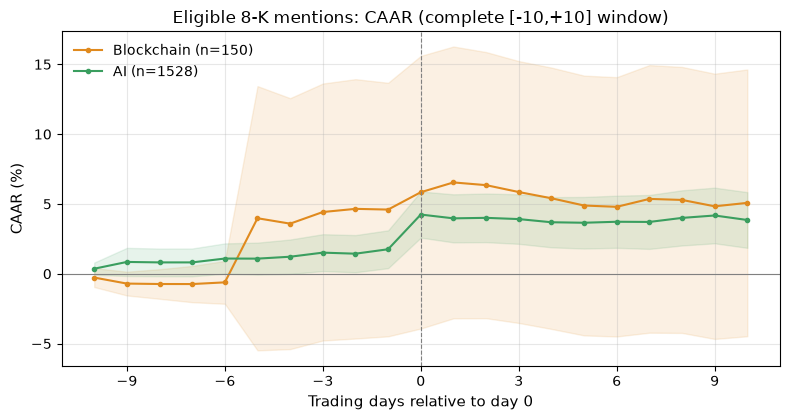

events in the event study: 1735 | benchmark used: {'market_model': 1617, 'market_adjusted': 118}


,sample,measure,n,mean,median,pct_positive,ci_low,ci_high,mde_80,t_pvalue,sign_pvalue,wilcoxon_pvalue,n_bmp,bmp_t,bmp_pvalue,boot_ci_low,boot_ci_high,boot_pvalue,n_clusters,cluster_pvalue
0,Blockchain,car_m1_p1,151,0.0546,-0.0089,45.6954,-0.0231,0.1322,0.1108,0.1669,0.3288,0.2863,146.0,0.5907,0.5556,-0.0042,0.1413,0.1371,46,0.2647
1,Blockchain,car_m5_p5,150,0.0550,-0.0084,46.0000,-0.0365,0.1465,0.1306,0.2367,0.3692,0.1977,146.0,0.6535,0.5145,-0.0140,0.1603,0.2182,46,0.2130
2,Blockchain,cav_m1_p1,146,2.0715,1.2415,73.9726,1.4578,2.6851,0.8757,0.0000,0.0000,0.0000,NaN,NaN,NaN,1.5012,2.7162,0.0000,45,0.0000
3,AI,car_m1_p1,1565,0.0230,0.0015,51.1821,0.0125,0.0336,0.0151,0.0000,0.3628,0.1012,1498.0,1.8883,0.0592,0.0127,0.0339,0.0000,60,0.0013
4,AI,car_m5_p5,1540,0.0252,0.0023,51.1039,0.0106,0.0398,0.0208,0.0007,0.4004,0.4191,1491.0,-0.5237,0.6005,0.0109,0.0399,0.0012,60,0.0147
5,AI,cav_m1_p1,1496,2.0616,1.5298,80.0134,1.8823,2.2409,0.2562,0.0000,0.0000,0.0000,NaN,NaN,NaN,1.8807,2.2400,0.0000,60,0.0000


In [8]:
daily = es.load_daily(daily_file)
market = es.load_market(wrds_dir / "crsp_daily_market_index.csv.gz")
main = announcements[announcements["in_main_sample"] == 1].reset_index(drop=True)
car_keep = ["event_id", "permno", "theme", "event_date", "new_name", "press_release", "event_month"]
measures = ["car_m1_p1", "car_m5_p5", "cav_m1_p1"]
wave_samples = {t: (lambda d, t=t: d["theme"] == t) for t in themes}

abnormal, estimates, _ = es.compute_abnormal_returns(main, daily, market, "market_model", "event_date")
cars = es.compute_cars(abnormal, estimates, main, keep_columns=car_keep)
announcement_summary = es.summarise_event_study(cars, wave_samples, measures)
fig, ax = plt.subplots(figsize=(8, 4.3))
es.plot_caar(abnormal, cars, "theme", {t: theme_colors[t] for t in themes}, ax,
             title="Eligible 8-K mentions: CAAR (complete [-10,+10] window)")
fig.tight_layout()
fig.savefig(output_dir / "ext_announcement_caar.png", dpi=150)
plt.show()
print("events in the event study:", len(cars), "| benchmark used:", estimates["benchmark_used"].value_counts().to_dict())
announcement_summary[announcement_summary["measure"].isin(["car_m1_p1", "car_m5_p5", "cav_m1_p1"])].round(4)

In [9]:
def run_extension_robustness(announcements, daily, market):
    """
    Re-estimate CAR[-1,+1] and CAR[-5,+5] under alternative samples and benchmarks.

    Parameters
    ----------
    announcements, daily, market : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
    """
    main = announcements[announcements["in_main_sample"] == 1]
    specifications = {
        "main": (main, "market_model"),
        "press-release 8-Ks only (EX-99)": (main[main["press_release"] == 1], "market_model"),
        "market-adjusted for all events": (main, "market_adjusted"),
        "incl. firms that also renamed": (announcements[announcements["blank_check"] == 0], "market_model"),
    }
    tables = []
    for label, (sample, model_name) in specifications.items():
        ab, est, _ = es.compute_abnormal_returns(sample, daily, market, model_name, "event_date")
        summary = es.summarise_event_study(es.compute_cars(ab, est, sample, keep_columns=car_keep), wave_samples,
                                           ["car_m1_p1", "car_m5_p5"])
        tables.append(summary.assign(specification=label))
    columns = ["specification", "sample", "measure", "n", "mean", "median", "t_pvalue", "sign_pvalue",
               "bmp_pvalue", "boot_pvalue", "cluster_pvalue"]
    return pd.concat(tables)[columns]


extension_robustness = run_extension_robustness(announcements, daily, market)
extension_robustness[extension_robustness["sample"].isin(themes)].pivot_table(
    index="specification", columns=["sample", "measure"], values="mean", sort=False).round(4)

sample                          Blockchain                  AI          
measure                          car_m1_p1 car_m5_p5 car_m1_p1 car_m5_p5
specification                                                           
main                                0.0546    0.0550    0.0230    0.0252
press-release 8-Ks only (EX-99)     0.0671    0.0793    0.0173    0.0171
market-adjusted for all events      0.0562    0.0603    0.0223    0.0226
incl. firms that also renamed       0.0647    0.0728    0.0229    0.0253

## Step 7: Blockchain vs AI
With hundreds of events per wave, the two modern waves can now be compared formally:
* bootstrap of the difference in mean CAR (AI − Blockchain);
* OLS of CAR on an AI dummy (Blockchain = reference), unconditional and with CRSP firm controls (log market cap,
  price, pre-event return and volatility). Preprocessing follows the Tutorial 4 pipeline; HC3 standard errors.

In [10]:
def bootstrap_wave_difference(data, outcome, group_a="AI", group_b="Blockchain", n_draws=es.N_BOOTSTRAP):
    """
    Bootstrap the difference in mean outcome between two waves.

    Parameters
    ----------
    data : pandas.DataFrame
    outcome : str
    group_a, group_b : str
    n_draws : int

    Returns
    -------
    dict
    """
    x = data.loc[data["theme"] == group_a, outcome].dropna().to_numpy()
    y = data.loc[data["theme"] == group_b, outcome].dropna().to_numpy()
    draws = rng.choice(x, (n_draws, len(x))).mean(axis=1) - rng.choice(y, (n_draws, len(y))).mean(axis=1)
    observed = x.mean() - y.mean()
    return {"outcome": outcome, "difference": f"{group_a} - {group_b}", "n_a": len(x), "n_b": len(y),
            "estimate": observed, "ci_low": np.percentile(draws, 2.5), "ci_high": np.percentile(draws, 97.5),
            "boot_pvalue": (np.abs(draws - observed) >= abs(observed)).mean()}


def fit_wave_regression(data, outcome, controls):
    """
    OLS of an outcome on the AI dummy (Blockchain = reference) with optional controls and HC3 errors.

    Parameters
    ----------
    data : pandas.DataFrame
    outcome : str
    controls : list of str

    Returns
    -------
    statsmodels.regression.linear_model.RegressionResultsWrapper
    """
    sample = data.dropna(subset=[outcome]).reset_index(drop=True)
    transformers = [("theme", OneHotEncoder(categories=[themes], drop="first", sparse_output=False), ["theme"])]
    if controls:
        transformers.append(("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), controls))
    design = ColumnTransformer(transformers, verbose_feature_names_out=False).fit_transform(sample)
    return sm.OLS(sample[outcome].astype(float), sm.add_constant(design.astype(float))).fit(cov_type="HC3")


crsp_controls = ["log_market_cap", "price", "pre_event_return", "pre_event_volatility"]
wave_data = cars.merge(es.build_crsp_characteristics(main, daily, market), on="event_id", how="left")
wave_data["price"] = np.log(wave_data["price"])          # log transform of a skewed variable (Tutorial 4)
wave_differences = pd.DataFrame([bootstrap_wave_difference(wave_data, m) for m in ["car_m1_p1", "car_m5_p5", "cav_m1_p1"]])
rows = []
for outcome in ["car_m1_p1", "car_m5_p5", "cav_m1_p1"]:
    for label, controls in [("(1) AI dummy only", []), ("(2) + CRSP controls", crsp_controls)]:
        results = fit_wave_regression(wave_data, outcome, controls)
        rows.append({"outcome": outcome, "model": label, "coef_AI": results.params["theme_AI"],
                     "robust_se": results.bse["theme_AI"], "p_value": results.pvalues["theme_AI"],
                     "n_obs": int(results.nobs), "r_squared": results.rsquared})
wave_regressions = pd.DataFrame(rows)
display(wave_differences.round(4))
wave_regressions.round(4)

,outcome,difference,n_a,n_b,estimate,ci_low,ci_high,boot_pvalue
0,car_m1_p1,AI - Blockchain,1565,151,-0.0316,-0.1218,0.0281,0.4338
1,car_m5_p5,AI - Blockchain,1540,150,-0.0298,-0.1355,0.0428,0.5354
2,cav_m1_p1,AI - Blockchain,1496,146,-0.0099,-0.6588,0.6094,0.9771


,outcome,model,coef_AI,robust_se,p_value,n_obs,r_squared
0,car_m1_p1,(1) AI dummy only,-0.0316,0.0398,0.4275,1716,0.0013
1,car_m1_p1,(2) + CRSP controls,-0.0259,0.0401,0.5178,1716,0.0108
2,car_m5_p5,(1) AI dummy only,-0.0298,0.0471,0.5263,1690,0.0007
3,car_m5_p5,(2) + CRSP controls,-0.0194,0.0452,0.6680,1690,0.0225
4,cav_m1_p1,(1) AI dummy only,-0.0099,0.3247,0.9757,1642,0.0000
5,cav_m1_p1,(2) + CRSP controls,0.1660,0.3095,0.5917,1642,0.0536


In [11]:
# Who announces? Firm characteristics at day -30 by wave (medians)
wave_data.groupby("theme")[["log_market_cap", "price", "pre_event_return", "pre_event_volatility"]].median().round(3)

,log_market_cap,price,pre_event_return,pre_event_volatility
theme,,,,
AI,14.302,3.064,-0.006,0.032
Blockchain,13.298,2.781,0.048,0.025


## Step 8: Renames and 8-K mentions side by side, and export
The table puts the rename results (notebook 03, primary sample) next to the 8-K mention results for the same
waves. The two are **different events** (a full rebranding vs. a keyword in a filing) and are not pooled.

In [12]:
rename_results = pd.read_excel(output_dir / "core_analysis_results.xlsx", sheet_name="rq2_event_study")
columns = ["sample", "measure", "n", "mean", "median", "bmp_pvalue", "boot_pvalue"]
comparison = pd.concat([
    rename_results[rename_results["sample"].isin(["Blockchain (primary)", "AI (primary)"])][columns]
        .assign(event_type="name change (primary sample)", sample=lambda d: d["sample"].str.replace(" (primary)", "")),
    announcement_summary[columns].assign(event_type="eligible 8-K mention"),
])
comparison = comparison[comparison["measure"].isin(["car_m1_p1", "car_m5_p5", "cav_m1_p1"])]
comparison.sort_values(["sample", "measure", "event_type"]).round(4)

,sample,measure,n,mean,median,bmp_pvalue,boot_pvalue,event_type
3,AI,car_m1_p1,1565,0.0230,0.0015,0.0592,0.0000,eligible 8-K mention
8,AI,car_m1_p1,8,0.0423,0.0254,0.4108,NaN,name change (primary sample)
4,AI,car_m5_p5,1540,0.0252,0.0023,0.6005,0.0012,eligible 8-K mention
9,AI,car_m5_p5,8,-0.0264,-0.1429,0.8327,NaN,name change (primary sample)
5,AI,cav_m1_p1,1496,2.0616,1.5298,NaN,0.0000,eligible 8-K mention
10,AI,cav_m1_p1,8,4.5169,3.9151,NaN,NaN,name change (primary sample)
0,Blockchain,car_m1_p1,151,0.0546,-0.0089,0.5556,0.1371,eligible 8-K mention
4,Blockchain,car_m1_p1,2,1.0131,1.0131,NaN,NaN,name change (primary sample)
1,Blockchain,car_m5_p5,150,0.0550,-0.0084,0.5145,0.2182,eligible 8-K mention
5,Blockchain,car_m5_p5,2,1.3405,1.3405,NaN,NaN,name change (primary sample)


In [13]:
with pd.ExcelWriter(output_dir / "announcement_extension_results.xlsx") as writer:
    for sheet, table in {"events": announcements, "event_study": announcement_summary,
                         "robustness": extension_robustness, "blockchain_vs_ai_bootstrap": wave_differences,
                         "blockchain_vs_ai_regressions": wave_regressions, "renames_vs_announcements": comparison,
                         "estimation": estimates}.items():
        table.to_excel(writer, sheet_name=sheet, index=False)
print("results written to", output_dir / "announcement_extension_results.xlsx")

results written to /Users/chunhanliao/Documents/FS_MADS/1_IntroDA/Group Project/IDA_Group7_whats_in_a_buzzword_submission/output/announcement_extension_results.xlsx


## Summary of the appendix (numbers from the run above)
**Sample.** EDGAR full-text search found 14,516 8-K filings mentioning the buzzwords; 11,746 belong to 2,047
listed CRSP common stocks. The 24-month-silence rule gives 1,892 events; after excluding blank-check shells and
firms already in the rename sample, **152 Blockchain and 1,583 AI events** remain (151 and 1,565 with a complete
CAR[−1,+1]). 145 AI and 3 Blockchain events are **re-entries** (an earlier mention exists before the 24-month
gap), so the rule identifies eligible mentions, not first adoption.

**Results (appendix, exploratory).**
* **AI (n = 1,565):** mean CAR[−1,+1] = +2.3% (t-test and bootstrap p < 0.001; month-clustered p = 0.001), but the
  median is only +0.15% and the sign test is not significant (p = 0.36); BMP p = 0.06. The average is driven by a
  minority of strong reactions. Press-release 8-Ks only: +1.7%.
* **Blockchain (n = 151):** mean +5.5%, median −0.9%, not significant (bootstrap p = 0.14, clustered p = 0.26).
* **Abnormal volume** rises by about 2.1 log points over [−1,+1] in both waves (p < 0.001).
* **AI − Blockchain:** −3.2 pp (95% CI −12.2 to +2.8, p = 0.43): no detectable difference.

**How to read this appendix.** A keyword in an 8-K is a broad proxy: it can describe an existing product, a risk
factor, a counterparty or general commentary, and the filing can lag a press release by up to four business days.
These results describe the market response to *eligible 8-K mentions*; they are not a rebranding effect, are not
pooled with the renames, and do not replace the small AI and Blockchain rename samples. Semantic validation of a
random sample of filings would be needed before calling them "technology announcements".